In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("All libraries imported successfully!")


All libraries imported successfully!


In [10]:
data = pd.read_csv("C:/Users/periy/Downloads/train.csv")

In [11]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [12]:
data.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [13]:
data.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [14]:
data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


#Why do we import Scikit-learn in Linear Regression?

Answer: Scikit-learn is a Python machine learning library used to build, train, test and evaluate machine learning models.

In [15]:
data = data[['Pclass', 'Age', 'SibSp',
             'Parch', 'Sex', 'Embarked', 'Fare']]

In [16]:
data.shape

(891, 7)

In [17]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Pclass    891 non-null    int64  
 1   Age       714 non-null    float64
 2   SibSp     891 non-null    int64  
 3   Parch     891 non-null    int64  
 4   Sex       891 non-null    object 
 5   Embarked  889 non-null    object 
 6   Fare      891 non-null    float64
dtypes: float64(2), int64(3), object(2)
memory usage: 48.9+ KB


In [18]:
data.isnull().sum()

Pclass        0
Age         177
SibSp         0
Parch         0
Sex           0
Embarked      2
Fare          0
dtype: int64

In [20]:
data.describe()

,Pclass,Age,SibSp,Parch,Fare
count,891.000000,714.000000,891.000000,891.000000,891.000000
mean,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.420000,0.000000,0.000000,0.000000
25%,2.000000,20.125000,0.000000,0.000000,7.910400
50%,3.000000,28.000000,0.000000,0.000000,14.454200
75%,3.000000,38.000000,1.000000,0.000000,31.000000
max,3.000000,80.000000,8.000000,6.000000,512.329200


In [21]:
data.dtypes

Pclass        int64
Age         float64
SibSp         int64
Parch         int64
Sex          object
Embarked     object
Fare        float64
dtype: object

In [22]:
data['Embarked'] = data['Embarked'].fillna(
    data['Embarked'].mode()[0]
)

In [25]:
data['Age'] = data['Age'].fillna(data['Age'].median())

In [26]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Pclass    891 non-null    int64  
 1   Age       891 non-null    float64
 2   SibSp     891 non-null    int64  
 3   Parch     891 non-null    int64  
 4   Sex       891 non-null    object 
 5   Embarked  891 non-null    object 
 6   Fare      891 non-null    float64
dtypes: float64(2), int64(3), object(2)
memory usage: 48.9+ KB


In [27]:
data.isnull().sum()

Pclass      0
Age         0
SibSp       0
Parch       0
Sex         0
Embarked    0
Fare        0
dtype: int64

#Q: Why did you use median imputation instead of mean imputation?

Professional answer:

"I used median imputation to handle missing values in the Age column because the median is less sensitive to outliers and provides a robust measure of central tendency."

One important professional practice: In a real ML project, calculate the median using training data only, then apply that same value to the test data. This prevents data leakage.

In [30]:
data.columns

Index(['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_male', 'Embarked_Q',
       'Embarked_S'],
      dtype='object')

In [32]:
x = data.drop('Fare',axis = 1)
y = data['Fare']

In [35]:
print(x.head())
print(y.head())

   Pclass   Age  SibSp  Parch  Sex_male  Embarked_Q  Embarked_S
0       3  22.0      1      0      True       False        True
1       1  38.0      1      0     False       False       False
2       3  26.0      0      0     False       False        True
3       1  35.0      1      0     False       False        True
4       3  35.0      0      0      True       False        True
0     7.2500
1    71.2833
2     7.9250
3    53.1000
4     8.0500
Name: Fare, dtype: float64


In [37]:
print("X shape:", x.shape)
print("y shape:", y.shape)

X shape: (891, 7)
y shape: (891,)


Now we need to divide our dataset into two parts:
1. Training data (80%) – Used to train the Linear Regression model.
2. Testing data (20%) – Used to evaluate how well the model predicts unseen data.

In [39]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2, random_state=42)

test_size=0.2 → 20% testing data and 80% training data.
random_state=42 → Keeps the split reproducible whenever you run the code.

In [41]:
print("X_train:", x_train.shape)
print("X_test:", x_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (712, 7)
X_test: (179, 7)
y_train: (712,)
y_test: (179,)


Create the Linear Regression Model
Now we are going to create our Machine Learning model.

In [43]:
model = LinearRegression()

In [44]:
model.fit(x_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [46]:
y_pred = model.predict(x_test)

In [47]:
print("Actual Fare:")
print(y_test.head(10))

print("Predicted Fare:")
print(y_pred[:10])

Actual Fare:
709    15.2458
439    10.5000
840     7.9250
720    33.0000
39     11.2417
290    78.8500
300     7.7500
333    18.0000
208     7.7500
136    26.2833
Name: Fare, dtype: float64
Predicted Fare:
[34.90043167 30.73993871 -2.31344407 47.20564404 28.76486767 68.67862096
  7.90273611  9.61620068  8.8619516  90.96015179]


In [48]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 20.809397730838647
MSE: 928.6125943999342
RMSE: 30.473145462848667
R2 Score: 0.39989994844402077


1. MAE – Mean Absolute Error
Your result: 20.81

On average, your predictions differ from the actual fares by approximately 20.81 fare units.

Lower MAE is better.
2. MSE – Mean Squared Error
Your result: 928.61

It calculates the average of squared prediction errors. Large errors receive more penalty.

Lower MSE is better.
3. RMSE – Root Mean Squared Error
Your result: 30.47

It is the square root of MSE. It expresses the error in the same units as the target variable (Fare).

Lower RMSE is better.
4. R² Score – Coefficient of Determination
Your result: 0.3999 (approximately 40%)

This means your model explains approximately 40% of the variation in ticket fares in the test dataset.

A higher R² is generally better. Your current model has room for improvement.
Interview question
Q: What is R² score in Linear Regression?

Answer:

"R² score measures how well a regression model explains the variation in the target variable. Its best possible value is 1. A higher value generally indicates better model performance."

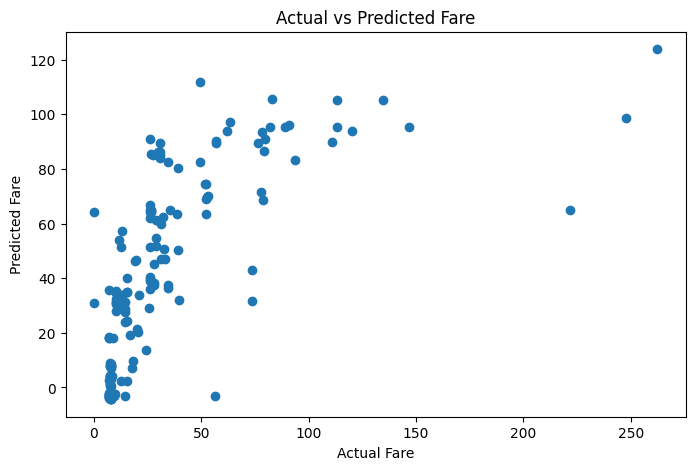

In [49]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")
plt.title("Actual vs Predicted Fare")

plt.show()

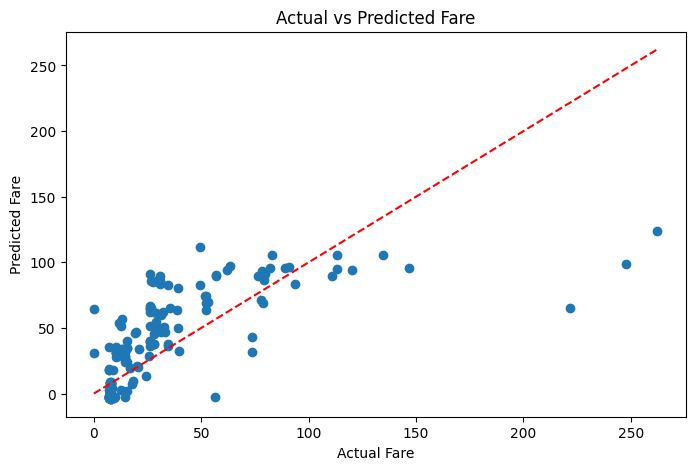

In [50]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linestyle='--'
)

plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")
plt.title("Actual vs Predicted Fare")

plt.show()

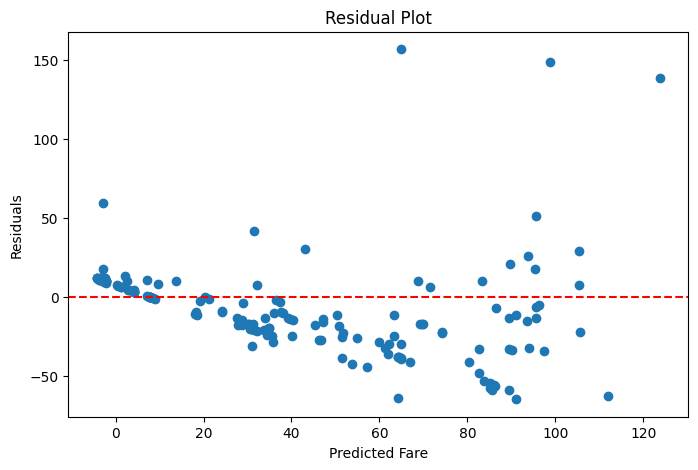

In [51]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals)
plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Fare")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.show()

#Residual Analysis
Residual means the difference between actual and predicted values.

Formula:
\[
Residual = Actual - Predicted
\]